# Training pipeline: weld inspection

This notebook is the training stage of Assignment 2. `uv run python main.py train`
converts it to a plain script and runs it top to bottom, so every cell must run
without manual steps.

1. Setup
2. The decision and its costs
3. Download the dataset
4. What the dataset contains
5. Finetune
6. Test results against the baselines
7. From boxes to weld decisions
8. Cost against threshold
9. What a person still has to check
10. Save what the app needs

`WELD_QUICK=1 uv run python main.py train` checks that every cell runs, in a
few minutes on a laptop: one epoch of `yolo11n` on 10% of the training images.
Its numbers mean nothing. Without it the notebook runs the full training.

In [1]:
import json
import os
import shutil

# Keep Ultralytics' per-batch progress bars out of the notebook; the cells
# below print their own summaries. Must be set before ultralytics is imported.
os.environ.setdefault("YOLO_VERBOSE", "False")

import matplotlib
import numpy as np
import pandas as pd

# main.py runs this notebook as a plain script. Outside Jupyter, switch to a
# non-interactive backend so a plot never opens a window and blocks the run.
try:
    get_ipython  # only defined inside Jupyter / IPython
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")

import matplotlib.pyplot as plt

import pipeline
from api_key import load_api_key


def show():
    """plt.show() inside Jupyter; just close the figure when run as a script."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


# Chart style: fixed categorical colour order, light grid, no top/right frame
plt.rcParams.update({
    "axes.prop_cycle": matplotlib.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                "#e87ba4", "#008300", "#6250d6", "#e34948"]),
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False,
})

SEED = 42
pipeline.ARTIFACTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 120)
print("running in Jupyter:", IN_NOTEBOOK)

running in Jupyter: True


## 2. The decision and its costs

One case is one weld seam, and the positive class is `Bad-weld`: the weld needs
repair. Each weld gets one of three decisions: pass it, send it to a person for
review, or fail it and send it to repair. The reasoning behind the figures is
in REPORT.md. The figures themselves live in `pipeline.py`, so the app prices
decisions exactly as this notebook does.

| Figure | Value | Source |
|---|---|---|
| Labour per hour, incl. employer costs | €40.3 | Eurostat 2025, euro-area industry |
| Share of welds that are bad (base rate) | 2% | TWI repair-rate survey, mild steel, all products |
| Visual check of one weld | 5 min | middle of the 2–8 min range (Therness) |
| Repair in the shop | 15 + 30 + 10 min and €10 of material | grind out, re-weld, re-inspect |
| Bad weld found at the customer | 1.5 × the €600 average sale: piece returned, replacement sent with priority transport, reputational damage | the shop's average sale |
| Bad welds a human inspector misses | 15% | Harris & Chaney (1969) |
| Welds a day | 270 | 3 inspectors, one per shift, each checking 90 welds in 7.5 h |
| Reviewers once the model is in | 1, on the day shift | night-shift welds wait until morning |
| A good weld failed by mistake | one needless shop repair | |

In [2]:
unit = pd.Series(pipeline.case_costs()).unstack()[pipeline.DECISIONS]
print(f"one visual check   EUR {pipeline.INSPECT_EUR:7.2f}")
print(f"one shop repair    EUR {pipeline.REPAIR_EUR:7.2f}")
print(f"one escaped weld   EUR {pipeline.ESCAPE_EUR:7.2f}  ({pipeline.ESCAPE_EUR / pipeline.REPAIR_EUR:.1f}x a shop repair)\n")
print("cost of one weld by truth and decision (EUR)\n" + unit.round(2).to_string() + "\n")

REFERENCE = {
    "do nothing": pipeline.cost_per_1000(pipeline.fixed_rates("pass")),
    "a person checks every weld": pipeline.cost_per_1000(pipeline.fixed_rates("review")),
}
for name, cost in REFERENCE.items():
    print(f"{name:28s} EUR {cost:8,.0f} per 1,000 welds")
check_all = pipeline.staffing(1.0)
print(f"\nchecking all {pipeline.WELDS_PER_DAY} welds a day takes {check_all['inspector hours per day']:.1f} "
      f"inspector hours, {check_all['inspectors needed']:.1f} full-time inspectors; "
      f"{pipeline.INSPECTORS} available can check {pipeline.review_capacity():.0%} of the welds")
print(f"today {pipeline.CURRENT_INSPECTORS} inspectors check every weld")

one visual check   EUR    3.36
one shop repair    EUR   46.94
one escaped weld   EUR  900.00  (19.2x a shop repair)

cost of one weld by truth and decision (EUR)
       pass  review   fail
bad   900.0  178.26  46.94
good    0.0    3.36  46.94

do nothing                   EUR   18,000 per 1,000 welds
a person checks every weld   EUR    6,856 per 1,000 welds

checking all 270 welds a day takes 22.5 inspector hours, 3.0 full-time inspectors; 1 available can check 33% of the welds
today 3 inspectors check every weld


## 3. Download the dataset

[`defect-detection-fxtd5/weld-defect-lze1x`](https://universe.roboflow.com/defect-detection-fxtd5/weld-defect-lze1x),
version 1, YOLO format, used as published. The export names its classes `0`, `1`
and `2`; `pipeline.download_dataset` writes a data file with the real names
(see `pipeline.CLASS_NAMES` for how they were matched). The download is skipped
when the files are already on disk.

In [3]:
DATA_YAML = pipeline.download_dataset(load_api_key())
print(DATA_YAML.read_text())

path: '/Users/vittoriofialdini/Desktop/Design AI Class/Ass 2/datasets/weld-defect-lze1x-1'
train: train/images
val: valid/images
test: test/images
names: ['Bad-weld', 'Good-weld', 'Defect']



## 4. What the dataset contains

### 4.1 Split sizes and instances per class

       images  Bad-weld boxes  Good-weld boxes  Defect boxes  Bad-weld images  Good-weld images  Defect images
split                                                                                                         
train     586             536              764           962              342               360            425
valid     168             134              235           225               91               110            108
test       84              64              110           107               42                49             53
total     838             734             1109          1294              475               519            586


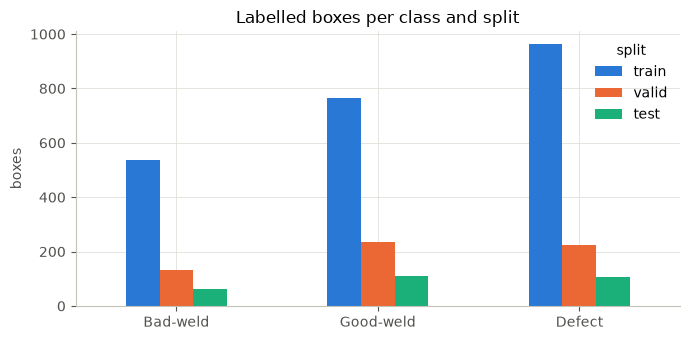

In [4]:
images, boxes = pipeline.load_labels()
names = pipeline.CLASS_NAMES

instances = images.groupby("split")[names].sum().reindex(pipeline.SPLITS)
images_with = (images[names] > 0).groupby(images["split"]).sum().reindex(pipeline.SPLITS)

summary = instances.add_suffix(" boxes").join(images_with.add_suffix(" images"))
summary.insert(0, "images", images["split"].value_counts().reindex(pipeline.SPLITS))
summary.loc["total"] = summary.sum()
print(summary.to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
instances.T.plot.bar(ax=ax, rot=0)
ax.set_ylabel("boxes")
ax.set_title("Labelled boxes per class and split")
fig.tight_layout()
fig.savefig(pipeline.ARTIFACTS_DIR / "dataset_instances.png", dpi=150)
show()

### 4.2 Cases: images and welds

Two ways to count the cases a decision is made on. Per image: does the photo
contain a bad weld or a marked defect? Per weld: every weld seam is labelled
either `Good-weld` or `Bad-weld`, while `Defect` boxes mark individual flaws,
usually inside a bad weld.

In [5]:
images["has_problem"] = (images["Bad-weld"] + images["Defect"]) > 0
cases = images.groupby("split")["has_problem"].agg(images="size", with_problem="sum")
cases = cases.reindex(pipeline.SPLITS)
cases["good welds only"] = cases["images"] - cases["with_problem"]
cases["problem share"] = (cases["with_problem"] / cases["images"]).round(2)
print("per image\n" + cases.to_string() + "\n")

welds = instances[["Good-weld", "Bad-weld"]].copy()
welds["bad share"] = (welds["Bad-weld"] / welds.sum(axis=1)).round(2)
print("per weld seam\n" + welds.to_string() + "\n")

defect_only = images[(images["Defect"] > 0) & (images["Bad-weld"] + images["Good-weld"] == 0)]
print("images with Defect boxes but no weld box:",
      defect_only["split"].value_counts().reindex(pipeline.SPLITS).to_dict())

per image
       images  with_problem  good welds only  problem share
split                                                      
train     586           457              129           0.78
valid     168           114               54           0.68
test       84            58               26           0.69

per weld seam
       Good-weld  Bad-weld  bad share
split                                
train        764       536       0.41
valid        235       134       0.36
test         110        64       0.37

images with Defect boxes but no weld box: {'train': 91, 'valid': 16, 'test': 14}


### 4.3 Object size

Box area as a share of the image. All images are 640 x 640, so a box under
0.25% of the image is smaller than 32 x 32 pixels, the usual cut-off for a
"small" object.

image sizes: {(640, 640)}
box area, % of image
            count   min   25%   50%   75%    max  small share
class                                                        
Bad-weld    734.0  0.25  1.78  4.16  7.34  87.30         0.00
Good-weld  1109.0  0.13  1.14  2.20  4.54  92.83         0.00
Defect     1294.0  0.03  0.72  1.24  2.15  39.22         0.04


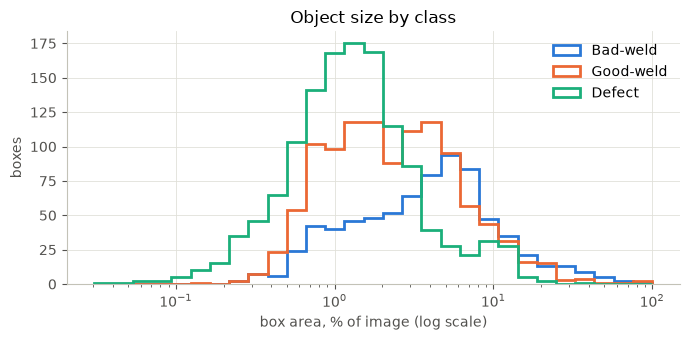

In [6]:
from PIL import Image

image_sizes = {Image.open(pipeline.DATA_DIR / s / "images" / n).size
               for s, n in zip(images["split"], images["image"])}
print("image sizes:", image_sizes)

size_stats = boxes.groupby("class")["area_pct"].describe(percentiles=[0.25, 0.5, 0.75]).reindex(names)
size_stats["small share"] = boxes.groupby("class")["area_pct"].apply(lambda a: (a < 0.25).mean())
print("box area, % of image")
print(size_stats[["count", "min", "25%", "50%", "75%", "max", "small share"]].round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.logspace(np.log10(boxes["area_pct"].min()), 2, 30)
for name in names:
    ax.hist(boxes.loc[boxes["class"] == name, "area_pct"], bins=bins, histtype="step", linewidth=2, label=name)
ax.set_xscale("log")
ax.set_xlabel("box area, % of image (log scale)")
ax.set_ylabel("boxes")
ax.set_title("Object size by class")
ax.legend()
fig.tight_layout()
fig.savefig(pipeline.ARTIFACTS_DIR / "dataset_box_sizes.png", dpi=150)
show()

### 4.4 Where the images come from

Many file names show the image is a frame cut from one of six videos
(`SampleV1_1` to `SampleV3_2`). Frames of the same video look alike, so a frame
in the test split may have a near-twin in the train split. The check below
compares every valid and test image with its closest train image using a
difference hash (`pipeline.dhash`); 10 or fewer differing bits out of 256 means
the two are near-duplicates.

In [7]:
print("images by source\n" + pd.crosstab(images["source"], images["split"])
      .reindex(columns=pipeline.SPLITS).to_string() + "\n")

images["train_distance"] = pipeline.nearest_train_distance(images)
images["near_duplicate"] = images["train_distance"] <= 10
for split in ["valid", "test"]:
    part = images[images["split"] == split]
    print(f"{split}: {len(part)} images, {int((part['train_distance'] == 0).sum())} identical to a "
          f"train image, {int(part['near_duplicate'].sum())} near-duplicates "
          f"({int(part.loc[part['source'] != 'other', 'near_duplicate'].sum())} of them video frames)")

images by source
split       train  valid  test
source                        
SampleV1_1     72     17     6
SampleV1_2     41     14     2
SampleV2_1    101     26    11
SampleV2_2     91     27    15
SampleV3_1     36     12     7
SampleV3_2     28      6     3
other         217     66    40



valid: 168 images, 0 identical to a train image, 15 near-duplicates (15 of them video frames)
test: 84 images, 0 identical to a train image, 8 near-duplicates (8 of them video frames)


## 5. Finetune

Both `yolo11n` and `yolo11s` start from their COCO weights and are finetuned
with the same settings:

- **Time limit:** each model gets at most 0.18 hours (about 11 minutes) of
  training, which overrides the epoch count, so the whole notebook fits in 30
  minutes on a Kaggle GPU. Ultralytics fits its learning-rate schedule to the
  epochs that fit in the time.
- **Early stopping:** training also stops when validation mAP50-95 has not
  improved for 20 epochs, and Ultralytics keeps the best epoch.
- **Speed settings:** images are cached in memory, batches hold 32 images, and
  the GPU is allowed non-deterministic kernels. Runs are faster but not
  bit-for-bit repeatable.

The model with the higher mAP50-95 on the **valid** split is kept and copied to
`weights/best.pt`; the test split plays no part in the choice.

A finished run is reused rather than retrained when `runs/<model>/done.json`
shows it was trained with exactly these settings. That lets the evaluation below
be re-run after changing a cost figure. A fresh copy of the repo has no `runs/`,
so it always trains.

In [8]:
import torch
from ultralytics import YOLO

QUICK = os.environ.get("WELD_QUICK") == "1"  # a test that the cells run, not a real model
VARIANTS = ["yolo11n"] if QUICK else ["yolo11n", "yolo11s"]
DEVICE = 0 if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
TRAIN_ARGS = {"epochs": 100, "time": 0.18, "patience": 20, "imgsz": 640, "batch": 32, "workers": 4,
              "cache": "ram", "seed": SEED, "deterministic": False}
if QUICK:
    TRAIN_ARGS.update(epochs=1, time=None, batch=4, workers=2, cache=False, fraction=0.1)
PRETRAINED = pipeline.RUNS_DIR / "pretrained"
PRETRAINED.mkdir(parents=True, exist_ok=True)
print(f"device {DEVICE}, models {VARIANTS}, {TRAIN_ARGS}")

candidates = []
for variant in VARIANTS:
    run = pipeline.RUNS_DIR / (f"{variant}-quick" if QUICK else variant)
    done = run / "done.json"
    if not QUICK and done.exists() and json.loads(done.read_text()) == TRAIN_ARGS:
        print(f"{variant}: reusing the finished run in {run.relative_to(pipeline.ROOT)}")
    else:
        YOLO(PRETRAINED / f"{variant}.pt").train(data=str(DATA_YAML), device=DEVICE, project=str(pipeline.RUNS_DIR),
                                                 name=run.name, exist_ok=True, **TRAIN_ARGS)
        done.write_text(json.dumps(TRAIN_ARGS))
    val = YOLO(run / "weights" / "best.pt").val(data=str(DATA_YAML), split="val", device=DEVICE, plots=False,
                                                 project=str(pipeline.RUNS_DIR), name=f"{run.name}-val", exist_ok=True)
    candidates.append({"model": variant, "run": run.name, "epochs run": len(pd.read_csv(run / "results.csv")),
                       "val AP50": val.box.map50, "val mAP50-95": val.box.map})

candidates = pd.DataFrame(candidates)
best = candidates.loc[candidates["val mAP50-95"].idxmax()]
CHOSEN, chosen_run = best["model"], pipeline.RUNS_DIR / best["run"]
shutil.copy(chosen_run / "weights" / "best.pt", pipeline.WEIGHTS_PATH)
if (chosen_run / "results.png").exists():
    shutil.copy(chosen_run / "results.png", pipeline.ARTIFACTS_DIR / "training_curves.png")
print(candidates.round(3).to_string(index=False))
print(f"\nkept {CHOSEN}, saved to {pipeline.WEIGHTS_PATH.relative_to(pipeline.ROOT)}")

device mps, models ['yolo11n', 'yolo11s'], {'epochs': 100, 'time': 0.18, 'patience': 20, 'imgsz': 640, 'batch': 32, 'workers': 4, 'cache': 'ram', 'seed': 42, 'deterministic': False}
yolo11n: reusing the finished run in runs/yolo11n


yolo11s: reusing the finished run in runs/yolo11s


  model     run  epochs run  val AP50  val mAP50-95
yolo11n yolo11n         125     0.757         0.484
yolo11s yolo11s          73     0.719         0.457

kept yolo11n, saved to weights/best.pt


## 6. Test results against the baselines

All three are scored on the same 84 test images.

- **Finetuned model:** Ultralytics' validator. Per-class precision and recall
  are at the confidence that maximises F1; AP50 and mAP50-95 cover all
  confidences.
- **COCO model, zero-shot:** its 80 classes include nothing like a weld, so it
  cannot score above zero on these classes. The cell lists what it predicts
  instead.
- **Trivial baseline:** predicts nothing, so its recall and AP are 0.

In [9]:
model = YOLO(pipeline.WEIGHTS_PATH)
test = model.val(data=str(DATA_YAML), split="test", device=DEVICE, plots=True,
                 project=str(pipeline.RUNS_DIR), name="test", exist_ok=True)

finetuned = f"finetuned {CHOSEN}"
rows = []
for i, c in enumerate(test.ap_class_index):
    p, r, ap50, ap = test.box.class_result(i)
    rows.append({"model": finetuned, "class": names[c], "precision": p, "recall": r, "AP50": ap50, "mAP50-95": ap})
rows.append({"model": finetuned, "class": "all", "precision": test.box.mp, "recall": test.box.mr,
             "AP50": test.box.map50, "mAP50-95": test.box.map})
for baseline in [f"COCO {CHOSEN}, zero-shot", "predicts nothing"]:
    rows += [{"model": baseline, "class": name, "precision": np.nan, "recall": 0.0, "AP50": 0.0, "mAP50-95": 0.0}
             for name in names + ["all"]]
metrics = pd.DataFrame(rows)
print(metrics.round(3).to_string(index=False))

# Predictions on every valid and test image, used from section 7 on
eval_images = images[images["split"].isin(["valid", "test"])].reset_index(drop=True)
assert eval_images["image"].is_unique
paths = [pipeline.DATA_DIR / s / "images" / n for s, n in zip(eval_images["split"], eval_images["image"])]
coco = YOLO(PRETRAINED / f"{CHOSEN}.pt")
predictions = {"finetuned": pipeline.predict_boxes(model, paths), "coco": pipeline.predict_boxes(coco, paths)}

test_images = set(eval_images.loc[eval_images["split"] == "test", "image"])
coco_test = predictions["coco"][predictions["coco"]["image"].isin(test_images) & (predictions["coco"]["conf"] >= 0.25)]
print(f"\nCOCO model on the test images: {len(coco_test)} boxes at confidence 0.25 or more, by class")
print(coco_test["class"].value_counts().head(8).to_string())

                  model     class  precision  recall  AP50  mAP50-95
      finetuned yolo11n  Bad-weld      0.697   0.750 0.742     0.499
      finetuned yolo11n Good-weld      0.794   0.735 0.792     0.529
      finetuned yolo11n    Defect      0.695   0.533 0.552     0.288
      finetuned yolo11n       all      0.728   0.673 0.695     0.439
COCO yolo11n, zero-shot  Bad-weld        NaN   0.000 0.000     0.000
COCO yolo11n, zero-shot Good-weld        NaN   0.000 0.000     0.000
COCO yolo11n, zero-shot    Defect        NaN   0.000 0.000     0.000
COCO yolo11n, zero-shot       all        NaN   0.000 0.000     0.000
       predicts nothing  Bad-weld        NaN   0.000 0.000     0.000
       predicts nothing Good-weld        NaN   0.000 0.000     0.000
       predicts nothing    Defect        NaN   0.000 0.000     0.000
       predicts nothing       all        NaN   0.000 0.000     0.000



COCO model on the test images: 39 boxes at confidence 0.25 or more, by class
class
bench           12
book             5
cat              4
tie              3
surfboard        2
person           2
baseball bat     2
broccoli         1


### 6.1 Confusion matrix

Test boxes, counting only predictions at a confidence of 0.25 or more, matched
to a labelled box at an IoU of 0.45. Ultralytics builds this matrix at the
validator's confidence, which is 0.001 for the AP numbers above, so every faint
box would count as an error; a second pass at 0.25 gives a matrix that reflects
what the model actually reports. `background` as the true class is a box the
model predicted where nothing is labelled; as the predicted class, it is a
labelled box the model missed.

predicted   Bad-weld  Good-weld  Defect  background
true                                               
Bad-weld          38         10       6          10
Good-weld         14         79       2          15
Defect             3          0      56          48
background        23         31      48           0


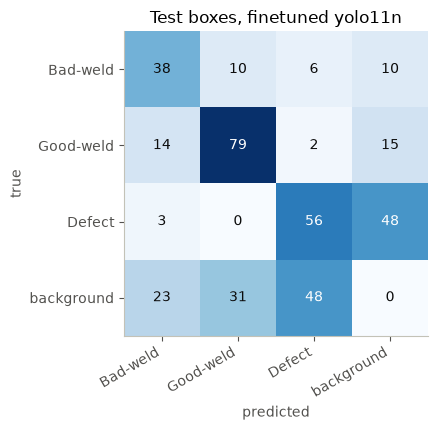

In [10]:
# plots=True is what makes Ultralytics fill the confusion matrix at all
at_025 = model.val(data=str(DATA_YAML), split="test", device=DEVICE, conf=0.25, plots=True,
                   project=str(pipeline.RUNS_DIR), name="test-conf025", exist_ok=True)
labels = names + ["background"]
cm = pd.DataFrame(at_025.confusion_matrix.matrix.T.astype(int), index=labels, columns=labels)
cm.index.name, cm.columns.name = "true", "predicted"
print(cm.to_string())

fig, ax = plt.subplots(figsize=(5.2, 4.4))
values = cm.to_numpy()
ax.imshow(values, cmap="Blues")
ax.grid(False)
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), labels)
for (i, j), v in np.ndenumerate(values):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > values.max() / 2 else "#0b0b0b")
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"Test boxes, {finetuned}")
fig.tight_layout()
fig.savefig(pipeline.ARTIFACTS_DIR / "detection_confusion_matrix.png", dpi=150)
show()

## 7. From boxes to weld decisions

The decision is made per weld, so the detector's boxes are turned into one score
per labelled weld seam (`pipeline.seam_scores`):

- A predicted `Bad-weld` or `Defect` box counts towards a seam when at least
  half of it lies inside the seam's box.
- The seam's score is the highest confidence among those boxes, and 0 when there
  are none.

`Defect` boxes count because, in the labels, they sit inside bad welds; the
first line below checks that. The COCO model gets the most generous reading:
any of its boxes, whatever the class, counts as evidence of a bad weld.

Images with `Defect` boxes but no weld box have no seam, so they are not cases.

seams with a labelled Defect box inside, all splits: {'Bad-weld': {'sum': 622, 'size': 734}, 'Good-weld': {'sum': 1, 'size': 1109}} 



class  Bad-weld  Good-weld
split                     
valid       134        235
test         64        110 



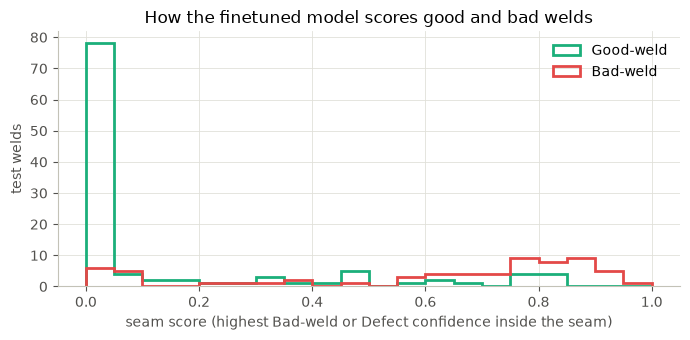

In [11]:
seams = boxes[boxes["class"].isin(["Bad-weld", "Good-weld"])].reset_index(drop=True)
labelled_defects = boxes[boxes["class"] == "Defect"].assign(conf=1.0)
contains_defect = pipeline.seam_scores(seams, labelled_defects) > 0
print("seams with a labelled Defect box inside, all splits:",
      contains_defect.groupby(seams["class"]).agg(["sum", "size"]).to_dict("index"), "\n")

seams = seams[seams["split"].isin(["valid", "test"])].merge(
    images[["split", "image", "source", "near_duplicate"]], on=["split", "image"])
seams["is_bad"] = seams["class"] == "Bad-weld"
seams["score"] = pipeline.seam_scores(seams, predictions["finetuned"]).to_numpy()
seams["score_coco"] = pipeline.seam_scores(seams, predictions["coco"], score_classes=None).to_numpy()
print(pd.crosstab(seams["split"], seams["class"]).reindex(["valid", "test"]).to_string(), "\n")

test_seams = seams[seams["split"] == "test"]
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, 1, 21)
for cls, color in [("Good-weld", "#1baf7a"), ("Bad-weld", "#e34948")]:
    ax.hist(test_seams.loc[test_seams["class"] == cls, "score"], bins=bins, histtype="step", linewidth=2,
            color=color, label=cls)
ax.set_xlabel("seam score (highest Bad-weld or Defect confidence inside the seam)")
ax.set_ylabel("test welds")
ax.set_title("How the finetuned model scores good and bad welds")
ax.legend()
fig.tight_layout()
fig.savefig(pipeline.ARTIFACTS_DIR / "seam_scores.png", dpi=150)
show()

## 8. Cost against threshold

With one threshold and no review, a weld fails when its score is at or above the
threshold and passes otherwise. For every threshold from 0 to 1, the shares of
bad and good welds that pass or fail come from the labelled welds, then get
reweighted to the 2% base rate (`pipeline.cost_per_1000`).

The threshold is chosen on the **valid** split, which has more welds than test,
and the test split then reports what it costs. That keeps the test cost honest:
it was not tuned on the welds it is measured on.

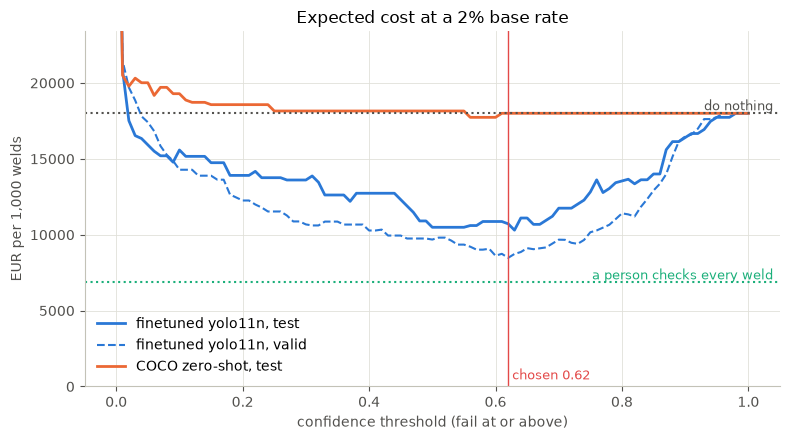

threshold chosen on valid: 0.62
  valid: recall 0.78, false alarm rate 0.081, EUR 8,478 per 1,000 welds
  test : recall 0.67, false alarm rate 0.091, EUR 10,719 per 1,000 welds
the cheapest threshold on test itself would be 0.63 (EUR 10,301)


In [12]:
splits = {s: seams[seams["split"] == s] for s in ["valid", "test"]}
curves = {(s, col): pipeline.sweep(df[col], df["is_bad"]) for s, df in splits.items() for col in ["score", "score_coco"]}
valid_curve, test_curve = curves[("valid", "score")], curves[("test", "score")]
THRESHOLD = float(valid_curve.loc[valid_curve["cost per 1000"].idxmin(), "threshold"])


def plot_cost_curve(band=None):
    """The sweep, with the reference costs; section 9 calls it again to add the review band."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(test_curve["threshold"], test_curve["cost per 1000"], color="#2a78d6", linewidth=2, label=f"{finetuned}, test")
    ax.plot(valid_curve["threshold"], valid_curve["cost per 1000"], color="#2a78d6", linestyle="--", label=f"{finetuned}, valid")
    coco_curve = curves[("test", "score_coco")]
    ax.plot(coco_curve["threshold"], coco_curve["cost per 1000"], color="#eb6834", linewidth=2, label="COCO zero-shot, test")
    references = list(REFERENCE.items())
    colors = ["#52514e", "#1baf7a"]
    if band is not None:
        low, high, cost = band
        references.append((f"model + review, {low:.2f} to {high:.2f}, test", cost))
        colors.append("#b07800")
    for (name, cost), color in zip(references, colors):
        ax.axhline(cost, color=color, linestyle=":" if color != "#b07800" else "-", linewidth=1.5)
        # the band's label goes under its line, so it cannot collide with the check-everything label just above
        ax.text(0.99, cost, name, ha="right", va="top" if color == "#b07800" else "bottom", color=color,
                fontsize=9, transform=ax.get_yaxis_transform())
    ax.axvline(THRESHOLD, color="#e34948", linewidth=1)
    ax.text(THRESHOLD, 0.02, f" chosen {THRESHOLD:.2f}", color="#e34948", fontsize=9, transform=ax.get_xaxis_transform())
    ax.set_ylim(0, 1.3 * REFERENCE["do nothing"])
    ax.set_xlabel("confidence threshold (fail at or above)")
    ax.set_ylabel("EUR per 1,000 welds")
    ax.set_title(f"Expected cost at a {pipeline.BASE_RATE:.0%} base rate")
    ax.legend(loc="lower left")
    fig.tight_layout()
    fig.savefig(pipeline.ARTIFACTS_DIR / "cost_curve.png", dpi=150)
    show()


plot_cost_curve()

print(f"threshold chosen on valid: {THRESHOLD:.2f}")
for s in splits:
    row = curves[(s, "score")].set_index("threshold").loc[THRESHOLD]
    print(f"  {s:5s}: recall {row['recall']:.2f}, false alarm rate {row['false alarm rate']:.3f}, "
          f"EUR {row['cost per 1000']:,.0f} per 1,000 welds")
print(f"the cheapest threshold on test itself would be {test_curve.loc[test_curve['cost per 1000'].idxmin(), 'threshold']:.2f} "
      f"(EUR {test_curve['cost per 1000'].min():,.0f})")

### 8.1 Which figures change the answer

The same choice, threshold on valid and cost on test, repeated for other
average sale prices and base rates. A bad weld that gets through costs 1.5 times
the average sale, so €300, €600 and €1,200 of sale give €450, €900 and €1,800 per
escaped weld. The second cell finds the average sale at which the cheapest of
the four options switches.

In [13]:
def model_alone_cost(base_rate=pipeline.BASE_RATE, **costs):
    """Test cost at the threshold that is cheapest on valid, under the given figures."""
    v = pipeline.sweep(splits["valid"]["score"], splits["valid"]["is_bad"], base_rate, **costs)
    t = float(v.loc[v["cost per 1000"].idxmin(), "threshold"])
    rates = pipeline.decision_rates(splits["test"]["score"], splits["test"]["is_bad"], t, t)
    return t, pipeline.cost_per_1000(rates, base_rate, **costs)


rows = []
for sale in [pipeline.AVERAGE_SALE_EUR / 2, pipeline.AVERAGE_SALE_EUR, pipeline.AVERAGE_SALE_EUR * 2]:
    escape = pipeline.ESCAPE_MULTIPLE * sale
    for base_rate in [0.01, 0.02, 0.03]:
        t, cost = model_alone_cost(base_rate, escape=escape)
        rows.append({"average sale EUR": sale, "escaped weld EUR": escape, "base rate": base_rate, "best threshold": t, "model alone": cost,
                     "do nothing": pipeline.cost_per_1000(pipeline.fixed_rates("pass"), base_rate, escape=escape),
                     "person checks all": pipeline.cost_per_1000(pipeline.fixed_rates("review"), base_rate, escape=escape)})
sensitivity = pd.DataFrame(rows)
sensitivity["cheapest"] = sensitivity[["model alone", "do nothing", "person checks all"]].idxmin(axis=1)
print(sensitivity.round(2).to_string(index=False))

 average sale EUR  escaped weld EUR  base rate  best threshold  model alone  do nothing  person checks all          cheapest
            300.0             450.0       0.01            0.82      3725.90      4500.0            4432.34       model alone
            300.0             450.0       0.02            0.82      7025.05      9000.0            5506.34 person checks all
            300.0             450.0       0.03            0.62      9515.26     13500.0            6580.35 person checks all
            600.0             900.0       0.01            0.73      7714.64      9000.0            5107.34 person checks all
            600.0             900.0       0.02            0.62     10719.10     18000.0            6856.34 person checks all
            600.0             900.0       0.03            0.62     13944.94     27000.0            8605.35 person checks all
           1200.0            1800.0       0.01            0.62     10446.39     18000.0            6457.34 person checks all


In [14]:
def model_review_cost(base_rate=pipeline.BASE_RATE, **costs):
    """Test cost of the review band that is cheapest on valid and fits the reviewers available."""
    b = pipeline.best_band(splits["valid"]["score"], splits["valid"]["is_bad"],
                           max_review=pipeline.review_capacity(), base_rate=base_rate, **costs)
    rates = pipeline.decision_rates(splits["test"]["score"], splits["test"]["is_bad"], b["low"], b["high"])
    return pipeline.cost_per_1000(rates, base_rate, **costs)


previous = None
print(f"cheapest option at a {pipeline.BASE_RATE:.0%} base rate as the average sale rises "
      f"(escaped weld = {pipeline.ESCAPE_MULTIPLE}x the sale):")
for sale in range(50, 3001, 50):
    escape = pipeline.ESCAPE_MULTIPLE * sale
    options = {"model + review": model_review_cost(escape=escape),
               "model alone": model_alone_cost(escape=escape)[1],
               "do nothing": pipeline.cost_per_1000(pipeline.fixed_rates("pass"), escape=escape),
               "person checks all": pipeline.cost_per_1000(pipeline.fixed_rates("review"), escape=escape)}
    cheapest = min(options, key=options.get)
    if cheapest != previous:
        print(f"  from EUR {sale:>5,} of sale (EUR {escape:,.0f} per escaped weld): {cheapest}")
        previous = cheapest

cheapest option at a 2% base rate as the average sale rises (escaped weld = 1.5x the sale):


  from EUR    50 of sale (EUR 75 per escaped weld): model + review


  from EUR   750 of sale (EUR 1,125 per escaped weld): person checks all


  from EUR 1,600 of sale (EUR 2,400 per escaped weld): model + review


## 9. What a person still has to check

Two thresholds: fail at or above `high`, pass below `low`, and send everything
in between to a person. A reviewed weld costs one visual check, and the
inspector still misses 15% of the bad ones.

The pair is chosen on the valid split: every combination on the 0.01 grid,
keeping only those whose review load fits the inspectors available
(`pipeline.review_capacity`), then the cheapest. The test split reports the
result against the three alternatives.

Reviewers are priced two ways. **Paid per minute:** a review costs only the 5
minutes it takes, as if the reviewer did other work the rest of the time.
**Paid per shift:** whoever reviews at all is on the payroll for a full 7.5-hour
shift, so the shop pays for that person whether the model sends them 10 welds or
90. Under shift pay the reviewer's spare time is free, so the cheapest band is
chosen again with that rule, and it can be wider.

The headline is per-minute pay: the band, the cost chart, the failures figure
and the app's default all use it. The shift-pay band is shown for comparison.

1 inspector(s) can check 33% of 270 welds a day
band chosen on valid: pass below 0.20, review from 0.20 to 0.82, fail at 0.82 or above
band chosen on valid with reviewers paid per shift: 0.05 to 0.86
with no limit on reviewers it would be 0.20 to 0.82, reviewing 21%

                                                      EUR per 1,000 welds  EUR per 1,000 welds, paid per shift  sent to review  bad welds caught  good welds failed  reviews per day  inspector hours per day  inspectors needed  people paid
policy                                                                                                                                                                                                                                       
do nothing                                                       18000.00                             18000.00            0.00              0.00               0.00             0.00                     0.00               0.00            0
a person checks ev

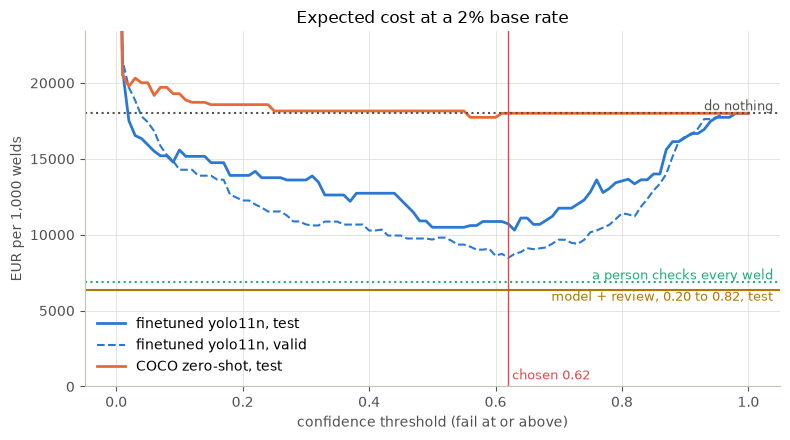

In [15]:
capacity = pipeline.review_capacity()
band = pipeline.best_band(splits["valid"]["score"], splits["valid"]["is_bad"], max_review=capacity)
band_shift = pipeline.best_band(splits["valid"]["score"], splits["valid"]["is_bad"], max_review=capacity,
                                paid_per_shift=True)
unlimited = pipeline.best_band(splits["valid"]["score"], splits["valid"]["is_bad"])
LOW, HIGH = band["low"], band["high"]
LOW_SHIFT, HIGH_SHIFT = band_shift["low"], band_shift["high"]
print(f"{pipeline.INSPECTORS} inspector(s) can check {capacity:.0%} of {pipeline.WELDS_PER_DAY} welds a day")
print(f"band chosen on valid: pass below {LOW:.2f}, review from {LOW:.2f} to {HIGH:.2f}, fail at {HIGH:.2f} or above")
print(f"band chosen on valid with reviewers paid per shift: {LOW_SHIFT:.2f} to {HIGH_SHIFT:.2f}")
print(f"with no limit on reviewers it would be {unlimited['low']:.2f} to {unlimited['high']:.2f}, "
      f"reviewing {unlimited['review share']:.0%}\n")

test_seams = splits["test"]
policies = {
    "do nothing": pipeline.fixed_rates("pass"),
    "a person checks every weld": pipeline.fixed_rates("review"),
    f"model alone, threshold {THRESHOLD:.2f}": pipeline.decision_rates(test_seams["score"], test_seams["is_bad"], THRESHOLD, THRESHOLD),
    f"model + review, {LOW:.2f} to {HIGH:.2f}": pipeline.decision_rates(test_seams["score"], test_seams["is_bad"], LOW, HIGH),
    f"model + review, {LOW_SHIFT:.2f} to {HIGH_SHIFT:.2f} (chosen with shift pay)":
        pipeline.decision_rates(test_seams["score"], test_seams["is_bad"], LOW_SHIFT, HIGH_SHIFT),
}
rows = []
for name, rates in policies.items():
    share = pipeline.review_share(rates)
    rows.append({"policy": name, "EUR per 1,000 welds": pipeline.cost_per_1000(rates),
                 "EUR per 1,000 welds, paid per shift": pipeline.cost_per_1000(rates, paid_per_shift=True),
                 "sent to review": share,
                 "bad welds caught": rates["bad"]["fail"] + rates["bad"]["review"] * (1 - pipeline.HUMAN_MISS_RATE),
                 "good welds failed": rates["good"]["fail"], **pipeline.staffing(share),
                 "people paid": pipeline.reviewers_paid(share)})
comparison = pd.DataFrame(rows).set_index("policy")
print(comparison.round(2).to_string())

decisions = pipeline.decide(test_seams["score"], LOW, HIGH)
counts = pd.crosstab(test_seams["class"], decisions).reindex(columns=pipeline.DECISIONS, fill_value=0)
print("\ntest welds by decision, with the band\n" + counts.rename_axis(columns="decision").to_string())

plot_cost_curve((LOW, HIGH, comparison.loc[f"model + review, {LOW:.2f} to {HIGH:.2f}", "EUR per 1,000 welds"]))

### 9.1 Which figures change the band

The scenarios of section 8.1 again, now with the band re-chosen on the valid
split for each one, under the same limit on reviewers. The cheapest column
compares all four options on the test split.

In [16]:
band_rows = []
for escape, base_rate in zip(sensitivity["escaped weld EUR"], sensitivity["base rate"]):
    b =pipeline.best_band(splits["valid"]["score"], splits["valid"]["is_bad"], max_review=capacity,
                           base_rate=base_rate, escape=escape)
    rates = pipeline.decision_rates(test_seams["score"], test_seams["is_bad"], b["low"], b["high"])
    band_rows.append({"band": f"{b['low']:.2f} to {b['high']:.2f}", "sent to review": pipeline.review_share(rates, base_rate),
                      "model + review": pipeline.cost_per_1000(rates, base_rate, escape=escape)})
with_band = pd.concat([sensitivity.drop(columns="cheapest"), pd.DataFrame(band_rows)], axis=1)
options = ["model + review", "model alone", "do nothing", "person checks all"]
with_band["cheapest"] = with_band[options].idxmin(axis=1)
print(with_band.round(2).to_string(index=False))

 average sale EUR  escaped weld EUR  base rate  best threshold  model alone  do nothing  person checks all         band  sent to review  model + review          cheapest
            300.0             450.0       0.01            0.82      3725.90      4500.0            4432.34 0.30 to 0.90            0.21         2401.79    model + review
            300.0             450.0       0.02            0.82      7025.05      9000.0            5506.34 0.20 to 0.86            0.23         3800.25    model + review
            300.0             450.0       0.03            0.62      9515.26     13500.0            6580.35 0.20 to 0.86            0.23         5334.01    model + review
            600.0             900.0       0.01            0.73      7714.64      9000.0            5107.34 0.20 to 0.86            0.22         3440.71    model + review
            600.0             900.0       0.02            0.62     10719.10     18000.0            6856.34 0.20 to 0.82            0.22         6372.8

### 9.2 Where the band goes wrong

The same test decisions split by where the image came from (a frame of one of
the six videos, or anything else) and by whether it is a near-duplicate of a
train image. A gap between the groups means the headline number leans on
images that resemble the training set.

The figure shows the bad welds the band passes, lowest score first, and the
good welds the model scores highest, which are the ones it sends to review or
fails.

              bad welds  bad passed  good welds  good failed
origin                                                      
other images         15        0.33          23         0.00
video frames         49        0.12          87         0.01 

                   bad welds  bad passed  good welds  good failed
duplicate                                                        
near-duplicate            10        0.10           8         0.00
no near-duplicate         54        0.19         102         0.01 



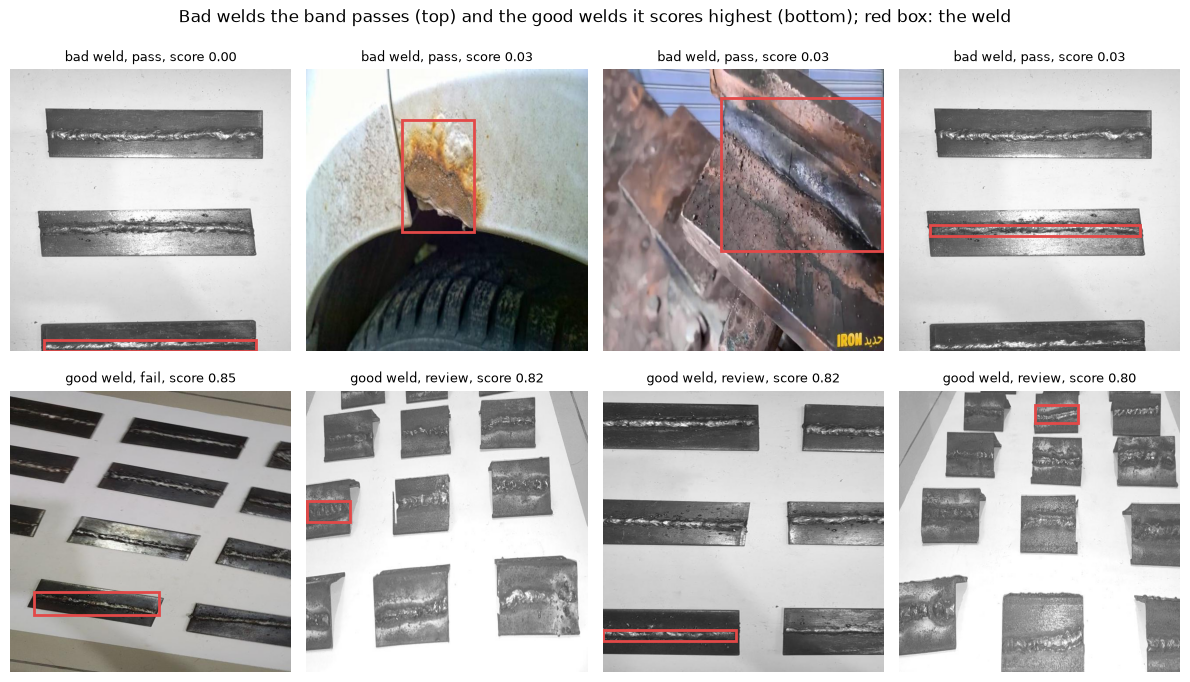

In [17]:
test_seams = test_seams.assign(decision=decisions,
                               origin=np.where(test_seams["source"] == "other", "other images", "video frames"),
                               duplicate=np.where(test_seams["near_duplicate"], "near-duplicate", "no near-duplicate"))
for column in ["origin", "duplicate"]:
    bad = test_seams[test_seams["is_bad"]].groupby(column)["decision"]
    good = test_seams[~test_seams["is_bad"]].groupby(column)["decision"]
    table = pd.DataFrame({"bad welds": bad.size(), "bad passed": bad.apply(lambda d: (d == "pass").mean()),
                          "good welds": good.size(), "good failed": good.apply(lambda d: (d == "fail").mean())})
    print(table.round(2).to_string(), "\n")

missed = test_seams[test_seams["is_bad"] & (test_seams["decision"] == "pass")].sort_values("score").head(4)
confusing = test_seams[~test_seams["is_bad"] & (test_seams["decision"] != "pass")].sort_values("score", ascending=False).head(4)
fig, axes = plt.subplots(2, 4, figsize=(12, 7.2))
for row_axes, cases, kind in [(axes[0], missed, "bad weld"), (axes[1], confusing, "good weld")]:
    for ax in row_axes:
        ax.axis("off")
    for ax, (_, case) in zip(row_axes, cases.iterrows()):
        picture = Image.open(pipeline.DATA_DIR / "test" / "images" / case["image"])
        width, height = picture.size
        ax.imshow(picture)
        ax.add_patch(plt.Rectangle(((case["x"] - case["w"] / 2) * width, (case["y"] - case["h"] / 2) * height),
                                   case["w"] * width, case["h"] * height, fill=False, color="#e34948", linewidth=2))
        ax.set_title(f"{kind}, {case['decision']}, score {case['score']:.2f}", fontsize=9)
fig.suptitle("Bad welds the band passes (top) and the good welds it scores highest (bottom); red box: the weld")
fig.tight_layout()
fig.savefig(pipeline.ARTIFACTS_DIR / "failures.png", dpi=120)
show()

## 10. Save what the app needs

The app never trains or predicts on the test set itself. It reads these files
and the weights in `weights/`.

In [18]:
columns = ["split", "image", "class", "is_bad", "x", "y", "w", "h", "source", "near_duplicate", "score", "score_coco"]
seams[columns].to_csv(pipeline.SEAMS_CSV, index=False)
metrics.to_csv(pipeline.METRICS_CSV, index=False)
cm.to_csv(pipeline.CONFUSION_CSV)
comparison.to_csv(pipeline.ARTIFACTS_DIR / "policy_comparison.csv")
operating_point = {"model": CHOSEN, "threshold": THRESHOLD, "low": LOW, "high": HIGH,
                   "low per shift": LOW_SHIFT, "high per shift": HIGH_SHIFT, "chosen on": "valid",
                   "device": str(DEVICE), "train args": TRAIN_ARGS,
                   "candidates": json.loads(candidates.to_json(orient="records"))}
pipeline.OPERATING_POINT_JSON.write_text(json.dumps(operating_point, indent=2))

# A few test photos for the app's examples, since datasets/ is not committed
examples_dir = pipeline.ARTIFACTS_DIR / "examples"
shutil.rmtree(examples_dir, ignore_errors=True)
examples_dir.mkdir()
test_photos = images[images["split"] == "test"].sort_values("image")
for photos in [test_photos[test_photos["Bad-weld"] > 0], test_photos[test_photos["Bad-weld"] + test_photos["Defect"] == 0]]:
    for name in photos["image"].head(3):
        shutil.copy(pipeline.DATA_DIR / "test" / "images" / name, examples_dir / name)
print("\n".join(sorted(str(p.relative_to(pipeline.ARTIFACTS_DIR)) for p in pipeline.ARTIFACTS_DIR.rglob("*.*"))))

cost_curve.png
dataset_box_sizes.png
dataset_instances.png
detection_confusion_matrix.csv
detection_confusion_matrix.png
detection_metrics.csv
examples/Good-Welding-images_4_jpeg_jpg.rf.7738f1dd7b939fe7c3467b60701c750f.jpg
examples/SampleV1_1_mp4-20_jpg.rf.ba4522defa765b3c12b45518ca2d029c.jpg
examples/SampleV1_1_mp4-20_jpg.rf.ffa9678b0dc67e1213c20b461209d215.jpg
examples/SampleV1_1_mp4-34_jpg.rf.f49679b578986081ec36e8465fb5724b.jpg
examples/SampleV1_2_mp4-37_jpg.rf.8472e22f6dc2895593aa3dc4073ede61.jpg
examples/SampleV2_2_mp4-74_jpg.rf.064fbd6780561de618985a5109e9f3cc.jpg
failures.png
operating_point.json
policy_comparison.csv
seam_scores.png
seams.csv
training_curves.png
